# 00 · ETL, preprocessing y EDA sobre datos REALES (Precios Claros vía Apify) — DataByte / RescateAlimento
**Capstone Samsung Innovation Campus · Producto 1: ETL + preprocessing + EDA + insumos para el dashboard**

## Qué hace este notebook
Toma el dataset que extrajo nuestro actor de Apify (`dataset_extractor_preciosclaros_2026-11-16.csv`, scraping de
[preciosclaros.gob.ar](https://www.preciosclaros.gob.ar/)) y lo convierte en información útil para decidir **qué vender, a qué precio y cuándo promocionar**.

| Etapa ETL | Input | Process | Output |
|---|---|---|---|
| **Extract** (Apify, ya hecho) | preciosclaros.gob.ar | Actor `PreciosClarosWebSite` programado desde n8n | CSV crudo (`data/raw/`) |
| **Transform** (este notebook) | CSV crudo | Calidad (nulos, duplicados, EAN válido), normalización (texto, unidades), outliers, variables nuevas | `data/processed/precios_limpios.csv` |
| **Load / visualizar** | tablas resumen | Agregaciones para el dashboard | `data/processed/*.csv` → Google Sheets / AppSheet / Looker Studio |

> **Honestidad de los datos (clave para el pitch):** el archivo tiene *registros* = un precio de un producto en una sucursal.
> No son «22.000 productos distintos»: abajo medimos cuántos EAN únicos hay. También cubre solo Córdoba y la corrida de Apify
> terminó por *timeout* a la hora (3.600 s), por lo que es una **muestra**, no el catálogo completo.

## 0. Configuración

In [1]:
import warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from sklearn.feature_selection import mutual_info_regression

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid"); pd.set_option("display.width", 170); pd.set_option("display.max_columns", 30)
SEED = 42

# El CSV se busca en el repo (../data/raw) y, si estás en Colab sin el repo, te pide subirlo.
CSV = next((f for c in (Path("../data/raw"), Path("data/raw"), Path(".")) for f in sorted(c.glob("dataset_extractor_preciosclaros*.csv"))), None)
if CSV is None:
    from google.colab import files          # solo existe en Colab
    CSV = Path(next(iter(files.upload())))
OUT = Path("../data/processed") if Path("../data").exists() else Path("data/processed")
OUT.mkdir(parents=True, exist_ok=True)

# Parámetros de las heurísticas (se pueden cambiar y re-ejecutar)
UMBRAL_OFERTON = 0.15      # un precio 15% o más bajo que la mediana del producto se considera «ofertón»
MIN_CADENAS_REF = 3        # para fijar un precio de referencia exigimos al menos 3 cadenas con el mismo EAN
print("Archivo:", CSV, "| Salida:", OUT)

Archivo: ../data/raw/dataset_extractor_preciosclaros_2026-11-16.csv | Salida: ../data/processed

## 1. Carga y diccionario de datos

In [2]:
raw = pd.read_csv(CSV)
resumen = pd.Series({
    "Registros (precio de un producto en una sucursal)": len(raw),
    "Productos únicos (EAN)": raw.ean.nunique(),
    "Cadenas (comercio)": raw.comercio.nunique(),
    "Sucursales (direcciones)": raw.direccion.nunique(),
    "Marcas": raw.marca.nunique(),
    "Provincias": raw.provincia.nunique(),
})
print(resumen.to_string())
print()
print(f"Cada producto aparece en promedio en {len(raw)/raw.ean.nunique():.1f} sucursales -> los 22k registros son ~{raw.ean.nunique():,} productos distintos.")

Registros (precio de un producto en una sucursal)    22438
Productos únicos (EAN)                                3009
Cadenas (comercio)                                       5
Sucursales (direcciones)                                27
Marcas                                                 633
Provincias                                               1

Cada producto aparece en promedio en 7.5 sucursales -> los 22k registros son ~3,009 productos distintos.

In [3]:
diccionario = pd.DataFrame({
    "columna": raw.columns,
    "tipo": raw.dtypes.astype(str).values,
    "nulos": raw.isna().sum().values,
    "valores_únicos": raw.nunique().values,
    "ejemplo": raw.iloc[0].astype(str).str[:38].values,
})
diccionario

,columna,tipo,nulos,valores_únicos,ejemplo
0,categoria,str,0,9,Alimentos congelados
1,comercio,str,0,5,Vea
2,direccion,str,0,27,Boulevard Chacabuco 199
3,ean,int64,0,3009,7790670050674
4,imagen,str,0,3009,https://imagenes.preciosclaros.gob.ar/
5,latitud,float64,0,27,-31.4225
6,localidad,str,0,3,CORDOBA
7,longitud,float64,0,27,-64.1823
8,marca,str,0,633,PATY
9,precio_lista,float64,0,1230,4490.0


## 2. Calidad de datos (nulos, duplicados, coherencia, EAN válido)
Regla de los apuntes: *no puede entrar un `NaN` al modelo*. Medimos primero, corregimos después y dejamos registro de cada regla.

In [4]:
def ean_valido(e):
    """Dígito verificador GS1 (sirve para EAN-13, EAN-8 y UPC-A rellenando con ceros a la izquierda)."""
    s = str(int(e)).zfill(13)
    if len(s) > 13:
        return False
    d = [int(c) for c in s]
    total = sum(x * (3 if i % 2 == 0 else 1) for i, x in enumerate(reversed(d[:-1])))
    return (10 - total % 10) % 10 == d[-1]

calidad = pd.DataFrame([
    ("Celdas nulas (todas las columnas)", int(raw.isna().sum().sum())),
    ("Filas duplicadas exactas", int(raw.duplicated().sum())),
    ("Duplicados por (EAN, cadena, dirección)", int(raw.duplicated(["ean", "comercio", "direccion"]).sum())),
    ("Precios <= 0", int((raw.precio_lista <= 0).sum())),
    ("precio_min > precio_lista", int((raw.precio_min_producto > raw.precio_lista).sum())),
    ("precio_lista > precio_max", int((raw.precio_lista > raw.precio_max_producto).sum())),
    ("Variantes de escritura de la localidad", raw.localidad.nunique()),
    ("EAN con dígito verificador inválido", int((~raw.ean.map(ean_valido)).sum())),
], columns=["chequeo", "resultado"])
calidad

,chequeo,resultado
0,Celdas nulas (todas las columnas),0
1,Filas duplicadas exactas,0
2,"Duplicados por (EAN, cadena, dirección)",0
3,Precios <= 0,0
4,precio_min > precio_lista,0
5,precio_lista > precio_max,0
6,Variantes de escritura de la localidad,3
7,EAN con dígito verificador inválido,0


In [5]:
print("Localidad tal cual viene:", raw.localidad.value_counts().to_dict())
print("\nRegistros por cadena:")
print(raw.comercio.value_counts().to_string())
print("\nDistribución por categoría:")
print((raw.categoria.value_counts(normalize=True) * 100).round(1).to_string())

Localidad tal cual viene: {'Córdoba': 12602, 'CORDOBA': 9743, 'Cordoba': 93}

Registros por cadena:
comercio
FARMACITY       12602
Disco            5643
Jumbo            2203
Vea              1897
Axion Energy       93

Distribución por categoría:
categoria
Perfumería y cuidado personal    44.1
Bebidas con alcohol              12.9
Limpieza                         11.9
Bebidas sin alcohol               9.0
Bebés                             8.5
Almacén                           6.4
Mascotas                          2.8
Frescos                           2.5
Alimentos congelados              1.9

**Lectura:** el dataset llega sin nulos, sin duplicados y con precios coherentes (min ≤ lista ≤ max), pero tiene tres problemas de **representatividad**
que hay que decir en voz alta: (1) solo Córdoba; (2) más de la mitad de los registros son de una farmacia (perfumería y cuidado personal domina);
(3) hay una estación de servicio (*Axion Energy*) que no es supermercado. Los problemas de *forma* sí se corrigen en la sección 3: la localidad tiene 3 grafías
y las presentaciones vienen como texto (`'500.0 ml'`).

## 3. Preprocessing (normalizar, crear variables, marcar outliers)
Decisiones: **no borramos** outliers (podrían ser productos caros reales, como un whisky); los **marcamos** y los tratamos con medidas robustas (mediana).

In [6]:
df = raw.copy()

# 3.1 Texto: una sola grafía de localidad, marcas y productos sin espacios ni minúsculas sueltas
df["localidad"] = df.localidad.str.strip().str.upper().replace({"CORDOBA": "Córdoba"}).replace({"CÓRDOBA": "Córdoba"})
df["marca"] = df.marca.fillna("SIN MARCA").str.strip().str.upper()
df["producto"] = df.producto.str.strip()

# 3.2 Presentación '500.0 ml' -> cantidad y unidad base para comparar «peras con peras» ($/litro, $/kg, $/unidad)
pres = df.presentacion.str.extract(r"^\s*([\d\.]+)\s*([a-zA-Z]+)")
df["cantidad"] = pd.to_numeric(pres[0], errors="coerce")
df["unidad"] = pres[1].str.lower()
FACTOR = {"gr": 1, "kg": 1000, "ml": 1, "cc": 1, "lt": 1000, "un": 1, "mt": 1}
BASE = {"gr": "g", "kg": "g", "ml": "ml", "cc": "ml", "lt": "ml", "un": "un", "mt": "m"}
df["unidad_base"] = df.unidad.map(BASE)
df["cantidad_base"] = df.cantidad * df.unidad.map(FACTOR)
# precio por kg / litro (g y ml *1000) o por unidad / metro
mult = df.unidad_base.map({"g": 1000, "ml": 1000, "un": 1, "m": 1})
df["precio_unitario_base"] = df.precio_lista / df.cantidad_base * mult

# 3.3 Segmentos de negocio
ALIMENTOS = ["Almacén", "Bebidas con alcohol", "Bebidas sin alcohol", "Frescos", "Alimentos congelados"]
df["es_alimento_bebida"] = df.categoria.isin(ALIMENTOS)
df["es_perecedero"] = df.categoria.isin(["Frescos", "Alimentos congelados"])   # los que más rinden para «rescate»
df["tipo_comercio"] = df.comercio.map({"FARMACITY": "Farmacia", "Axion Energy": "Estación de servicio"}).fillna("Supermercado")
df["marca_propia"] = df.marca.isin(["FARMACITY", "FARMACITY BEBÉ"])            # única marca propia detectable en este dataset

# 3.4 Outliers: z robusto (mediana y MAD) del log-precio dentro de cada categoría. Se MARCAN, no se borran.
lp = np.log(df.precio_lista)
med = lp.groupby(df.categoria).transform("median")
mad = (lp - med).abs().groupby(df.categoria).transform("median") * 1.4826
df["z_robusto"] = (lp - med) / mad
df["atipico"] = df.z_robusto.abs() > 3.5

print(f"Unidad no reconocida: {df.cantidad_base.isna().sum()} filas | Atípicos marcados: {df.atipico.sum()} ({df.atipico.mean():.1%})")
df[["producto", "presentacion", "cantidad_base", "unidad_base", "precio_lista", "precio_unitario_base", "atipico"]].sample(8, random_state=SEED)

Unidad no reconocida: 0 filas | Atípicos marcados: 237 (1.1%)

,producto,presentacion,cantidad_base,unidad_base,precio_lista,precio_unitario_base,atipico
12135,Alimento para Perros con Leche Pouch Pets Class 85 Gr,90.0 gr,90.0,g,1400.0,15555.555556,False
5980,Vino Tinto Malbec Ojo De Buen Cubero 750 Ml,750.0 ml,750.0,ml,14950.0,19933.333333,False
2561,Toallitas Humedas Bebe Hora Libre Antibacterial Aloe Vera Farmacity Bebe 30 Un,30.0 un,30.0,un,5130.0,171.000000,False
17714,Desodorante Aerosol Men Rexona 150 Ml,150.0 ml,150.0,ml,5219.5,34796.666667,False
898,Chocolate Clasico 70 % Cacao Fel Fort 50 Gr,50.0 gr,50.0,g,5200.0,104000.000000,False
18505,Shampoo Anti Amarillo Biferdil 295 Ml,295.0 ml,295.0,ml,14100.0,47796.610169,False
19014,Balsamo con Acido Hialuronico Capilatis 350 Ml,350.0 ml,350.0,ml,14400.0,41142.857143,False
7974,Agua Saborizada Citrus con Gas H2Oh! 1.5 Lt,1.5 lt,1500.0,ml,3050.0,2033.333333,False


In [7]:
# Validación del ETL: lo que sale tiene que cumplir reglas (si alguna falla, el pipeline avisa)
reglas = {
    "sin nulos en campos clave": df[["ean", "comercio", "categoria", "precio_lista"]].notna().all().all(),
    "una sola grafía de localidad": df.localidad.nunique() == 1,
    "precios positivos": (df.precio_lista > 0).all(),
    "unidad base reconocida en el 100%": df.cantidad_base.notna().all(),
}
pd.Series(reglas).map({True: "OK", False: "REVISAR"})

sin nulos en campos clave            OK
una sola grafía de localidad         OK
precios positivos                    OK
unidad base reconocida en el 100%    OK
dtype: str

## 4. EDA — distribuciones (justifica usar la **mediana** y no el promedio)
Apunte de la clase: *promedio no, porque se achatan los valores; mediana o moda como referencia.* Lo comprobamos con datos.

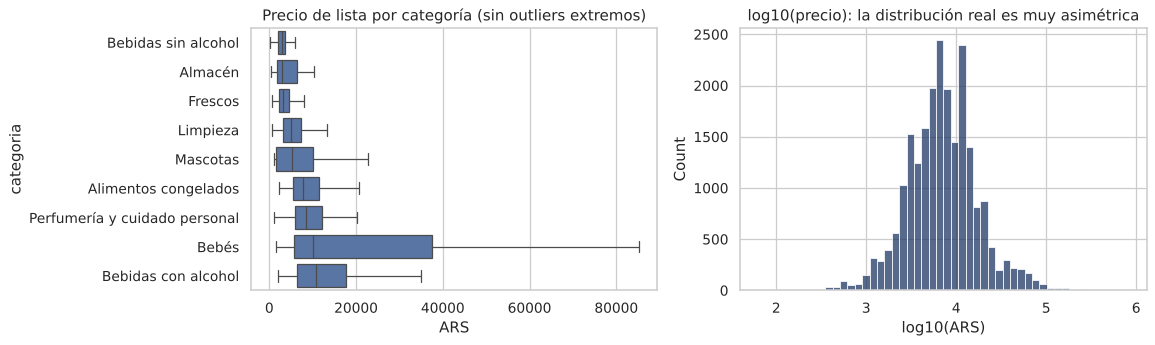

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
orden = df.groupby("categoria").precio_lista.median().sort_values().index
sns.boxplot(data=df, y="categoria", x="precio_lista", order=orden, ax=ax[0], showfliers=False)
ax[0].set_title("Precio de lista por categoría (sin outliers extremos)"); ax[0].set_xlabel("ARS")
sns.histplot(np.log10(df.precio_lista), bins=50, ax=ax[1], color="#1F3864")
ax[1].set_title("log10(precio): la distribución real es muy asimétrica"); ax[1].set_xlabel("log10(ARS)")
plt.tight_layout()

In [9]:
forma = pd.DataFrame({
    "media": [df.precio_lista.mean()], "mediana": [df.precio_lista.median()],
    "moda": [df.precio_lista.mode().iloc[0]],
    "sesgo (precio)": [stats.skew(df.precio_lista)], "sesgo (log precio)": [stats.skew(np.log(df.precio_lista))],
}).round(2)
print(f"La media (${df.precio_lista.mean():,.0f}) es {df.precio_lista.mean() / df.precio_lista.median() - 1:.0%} mayor que la mediana (${df.precio_lista.median():,.0f}): unos pocos productos caros 'tiran' el promedio hacia arriba.")
forma

La media ($10,819) es 57% mayor que la mediana ($6,890): unos pocos productos caros 'tiran' el promedio hacia arriba.

,media,mediana,moda,sesgo (precio),sesgo (log precio)
0,10818.85,6890.0,7990.0,14.51,0.13


## 5. EDA — correlaciones lineales y no lineales
El cronograma pide ambas. **Pearson** mide relación lineal; **Spearman** relación monótona (más robusta a colas largas); la **información mutua** captura relaciones no lineales con variables categóricas.

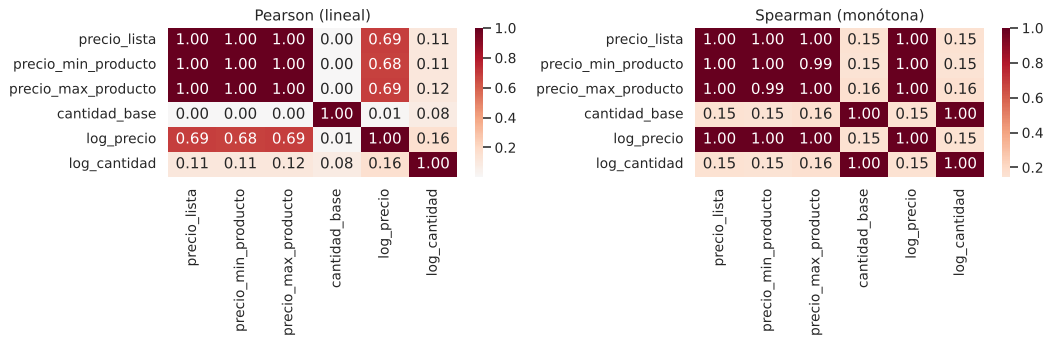

In [10]:
num = df[["precio_lista", "precio_min_producto", "precio_max_producto", "cantidad_base"]].copy()
num["log_precio"] = np.log(df.precio_lista); num["log_cantidad"] = np.log(df.cantidad_base)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.heatmap(num.corr("pearson"), annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax[0]); ax[0].set_title("Pearson (lineal)")
sns.heatmap(num.corr("spearman"), annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax[1]); ax[1].set_title("Spearman (monótona)")
plt.tight_layout()

In [11]:
X = pd.DataFrame({
    "categoria": df.categoria.astype("category").cat.codes,
    "comercio": df.comercio.astype("category").cat.codes,
    "marca": df.marca.astype("category").cat.codes,
    "unidad_base": df.unidad_base.astype("category").cat.codes,
    "log_cantidad": np.log(df.cantidad_base),
})
mi = mutual_info_regression(X, np.log(df.precio_lista), discrete_features=[True, True, True, True, False], random_state=SEED)
pd.Series(mi, index=X.columns, name="información mutua con log(precio)").sort_values(ascending=False).round(3)

marca           4.102
log_cantidad    3.003
categoria       1.145
comercio        0.750
unidad_base     0.608
Name: información mutua con log(precio), dtype: float64

**Lectura:** la **marca**, el **tamaño** de la presentación y la **categoría** explican más del precio que la cadena donde se vende. Es decir: el precio depende sobre todo *de qué producto es*;
la diferencia entre cadenas es un diferencial más chico, que es justo el que Diana quiere explotar (§6).
*Cuidado:* la marca tiene 633 valores y la información mutua tiende a inflarse con variables de alta cardinalidad; por eso la tomamos como una señal de orden, no como una medida exacta.

## 6. Heurística económica: precio de referencia, «ofertones» y marcas propias
Reglas mentales del equipo, ahora verificadas con datos: (1) se toma como referencia la **mediana** del mismo EAN entre cadenas; (2) una promoción real es un precio claramente por debajo de esa referencia; (3) la **marca propia** de una cadena suele ser más barata que la marca líder (se cumple en la mayoría de los casos, con excepciones: lo verificamos abajo).

In [12]:
# Un precio por (EAN, cadena): mediana entre sus sucursales
pc = df.groupby(["ean", "comercio"], as_index=False).agg(
    producto=("producto", "first"), categoria=("categoria", "first"), marca=("marca", "first"), precio=("precio_lista", "median"))
ref = pc.groupby("ean").agg(n_cadenas=("comercio", "nunique"), p_min=("precio", "min"), p_med=("precio", "median"),
                            p_max=("precio", "max"), p_media=("precio", "mean")).reset_index()
ref["spread_pct"] = (ref.p_max - ref.p_min) / ref.p_med * 100
comparables = ref[ref.n_cadenas >= 2]
print(f"{len(comparables):,} de {len(ref):,} productos se venden en 2 o más cadenas (comparables).")
print(f"Diferencia mediana entre la cadena más cara y la más barata: {comparables.spread_pct.median():.1f}% | el 25% de los productos tiene brecha > {comparables.spread_pct.quantile(.75):.1f}%")
refuerte = ref[ref.n_cadenas >= MIN_CADENAS_REF]
dif = ((refuerte.p_media - refuerte.p_med).abs() / refuerte.p_med)
print(f"Con >= {MIN_CADENAS_REF} cadenas ({len(refuerte)} productos): el promedio se aleja más de 2% de la mediana en el {(dif > .02).mean():.0%} de los casos.")
print("Los spreads más altos pueden ser oportunidades reales o ERRORES de carga del comercio (p. ej. un agua de 1,5 L a $64): hay que auditarlos antes de actuar.")
comparables.sort_values("spread_pct", ascending=False).merge(pc.drop_duplicates("ean")[["ean", "producto", "categoria"]], on="ean").head(10)

1,842 de 3,009 productos se venden en 2 o más cadenas (comparables).
Diferencia mediana entre la cadena más cara y la más barata: 3.4% | el 25% de los productos tiene brecha > 7.4%
Con >= 3 cadenas (998 productos): el promedio se aleja más de 2% de la mediana en el 27% de los casos.
Los spreads más altos pueden ser oportunidades reales o ERRORES de carga del comercio (p. ej. un agua de 1,5 L a $64): hay que auditarlos antes de actuar.

,ean,n_cadenas,p_min,p_med,p_max,p_media,spread_pct,producto,categoria
0,7792222002827,3,500.0,550.0,1120.0,723.333333,112.727273,Pastillas Naranja DRF 23 Gr,Almacén
1,7791813421368,4,3390.0,3450.0,7000.0,4322.500000,104.637681,Gaseosa Tonica Regular Paso de los Toros 1.5 Lt,Bebidas sin alcohol
2,7791813421382,4,3390.0,3450.0,7000.0,4322.500000,104.637681,Gaseosa Pomelo Paso de los Toros 1.5 Lt,Bebidas sin alcohol
3,7790895003875,4,64.0,2524.5,2600.0,1928.250000,100.455536,Agua Mineral sin Gas Bonaqua 1.5 Lt,Bebidas sin alcohol
4,7791813420385,3,1600.0,1600.0,3100.0,2100.000000,93.750000,Gaseosa Pomelo Paso de los Toros 500 Cc,Bebidas sin alcohol
5,7790895001451,3,4100.0,4100.0,7800.0,5333.333333,90.243902,Coca Cola Light Sabor Liviano 1.5 Lt,Bebidas sin alcohol
6,7790895000454,4,4100.0,4145.0,7800.0,5047.500000,89.264174,Gaseosa Naranja Fanta 1.5 Lt,Bebidas sin alcohol
7,7790895010088,4,4100.0,4145.0,7800.0,5047.500000,89.264174,Gaseosa Pomelo Schweppes Zero 1.5 Lt,Bebidas sin alcohol
8,7790895067556,4,4100.0,4145.0,7800.0,5047.500000,89.264174,Coca Cola sin Azucar 1.5 Lt,Bebidas sin alcohol
9,7790895064173,4,4100.0,4145.0,7800.0,5047.500000,89.264174,Gaseosa Lima Limon Sprite Zero 1.5 Lt,Bebidas sin alcohol


In [13]:
# «Ofertón»: precio de la cadena <= (1 - UMBRAL) x mediana de referencia (solo productos con >= 3 cadenas)
pc2 = pc.merge(refuerte[["ean", "p_med", "n_cadenas"]], on="ean")
pc2["vs_mediana_pct"] = (pc2.precio / pc2.p_med - 1) * 100
pc2["oferton"] = pc2.precio <= pc2.p_med * (1 - UMBRAL_OFERTON)
ofertones = pc2.groupby("comercio").agg(productos_comparados=("ean", "nunique"), ofertones=("oferton", "sum"))
ofertones["% ofertones"] = (ofertones.ofertones / ofertones.productos_comparados * 100).round(1)
ofertones

,productos_comparados,ofertones,% ofertones
comercio,,,
Axion Energy,55,5,9.1
Disco,991,0,0.0
FARMACITY,236,4,1.7
Jumbo,985,0,0.0
Vea,876,44,5.0


In [14]:
# Posicionamiento: índice de precio de cada cadena (100 = mediana del mercado en los mismos productos)
pos = pc2.groupby("comercio").agg(productos=("ean", "nunique"), indice_precio=("vs_mediana_pct", lambda s: 100 + s.median()))
pos["indice_precio"] = pos.indice_precio.round(1)
# Cuántas veces es la más barata (entre productos comparables en 2+ cadenas)
barata = pc[pc.ean.isin(comparables.ean)].loc[lambda d: d.groupby("ean").precio.transform("min") == d.precio].groupby("comercio").ean.nunique()
pos["veces_mas_barata"] = barata
pos["% de comparables donde es la más barata"] = (pos.veces_mas_barata / len(comparables) * 100).round(1)
pos.sort_values("indice_precio")

,productos,indice_precio,veces_mas_barata,% de comparables donde es la más barata
comercio,,,,
Vea,876,96.5,953,51.7
Disco,991,100.0,352,19.1
Jumbo,985,100.0,699,37.9
FARMACITY,236,100.2,147,8.0
Axion Energy,55,140.4,10,0.5


In [15]:
# Marca propia (FARMACITY) vs el resto: precio por unidad base dentro de la misma categoría y unidad
base = df[df.precio_unitario_base.notna() & ~df.atipico]
g = base.groupby(["categoria", "unidad_base", "marca_propia"]).precio_unitario_base.median().unstack("marca_propia").dropna()
g.columns = ["otras_marcas", "marca_propia"]
g["marca_propia_vs_otras_%"] = ((g.marca_propia / g.otras_marcas - 1) * 100).round(1)
g = g.reset_index()
print("Mediana del precio por unidad base. Negativo = la marca propia es más barata.")
print("Comparación GRUESA: dentro de una categoría mezcla productos distintos; sirve como señal, no como prueba.")
g

Mediana del precio por unidad base. Negativo = la marca propia es más barata.
Comparación GRUESA: dentro de una categoría mezcla productos distintos; sirve como señal, no como prueba.

,categoria,unidad_base,otras_marcas,marca_propia,marca_propia_vs_otras_%
0,Bebés,ml,28982.50000,19980.000000,-31.1
1,Bebés,un,505.20000,173.333333,-65.7
2,Limpieza,un,2300.00000,119.800000,-94.8
3,Perfumería y cuidado personal,g,55585.00000,19500.000000,-64.9
4,Perfumería y cuidado personal,ml,33752.50000,42884.615385,27.1
5,Perfumería y cuidado personal,un,571.40625,117.000000,-79.5


In [16]:
# ¿En qué categorías se separan más los precios entre cadenas? (mediana del spread de los productos comparables)
brecha_cat = comparables.merge(pc.drop_duplicates("ean")[["ean", "categoria"]], on="ean").groupby("categoria").agg(
    productos=("ean", "size"), brecha_mediana_pct=("spread_pct", "median"), brecha_p75_pct=("spread_pct", lambda x: x.quantile(.75))).round(1)
brecha_cat.sort_values("brecha_mediana_pct", ascending=False)

,productos,brecha_mediana_pct,brecha_p75_pct
categoria,,,
Almacén,46,11.6,21.8
Perfumería y cuidado personal,235,7.6,13.8
Frescos,80,6.1,8.9
Bebés,68,6.0,11.2
Mascotas,110,4.8,7.9
Bebidas sin alcohol,349,4.4,9.6
Limpieza,335,3.2,6.6
Alimentos congelados,89,2.0,4.4
Bebidas con alcohol,530,1.7,3.3


**Cómo usamos esto para decidir (puente al Score del bot):** el precio de referencia del bot es la **mediana de la competencia** (`precio_lista` del catálogo). Un lote que vence se rescata
bajando el precio hacia el piso que marca el mercado: nunca por debajo del mínimo observado (`precio_min`), y con un descuento proporcional a la urgencia.

## 7. Foco RescateAlimento: alimentos y bebidas, y perecederos

                                                      registros  productos  precio_mediano
es_alimento_bebida                                                                        
Otros rubros (perfumería, limpieza, bebés, mascotas)      15122       1420          7990.0
Alimentos y bebidas                                        7316       1589          4790.0

Perecederos (frescos + congelados): 983 registros, 173 productos, en 4 cadenas; precio mediano $4,600.

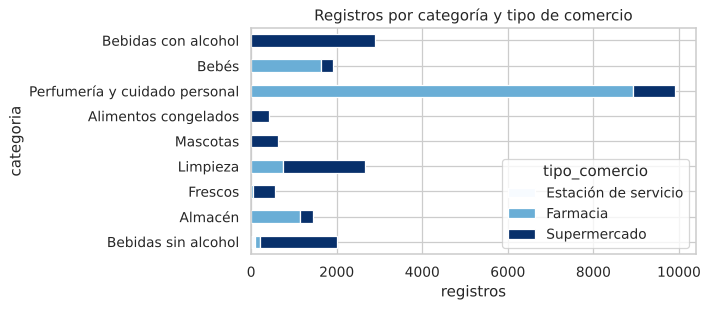

In [17]:
foco = df.groupby("es_alimento_bebida").agg(registros=("ean", "size"), productos=("ean", "nunique"), precio_mediano=("precio_lista", "median"))
foco.index = foco.index.map({True: "Alimentos y bebidas", False: "Otros rubros (perfumería, limpieza, bebés, mascotas)"})
print(foco.round(0).to_string())
per = df[df.es_perecedero]
print(f"\nPerecederos (frescos + congelados): {len(per):,} registros, {per.ean.nunique()} productos, en {per.comercio.nunique()} cadenas; precio mediano ${per.precio_lista.median():,.0f}.")
fig, ax = plt.subplots(figsize=(8, 3.6))
(df.groupby(["categoria", "tipo_comercio"]).size().unstack(fill_value=0).loc[orden]).plot(kind="barh", stacked=True, ax=ax, colormap="Blues")
ax.set_title("Registros por categoría y tipo de comercio"); ax.set_xlabel("registros"); plt.tight_layout()

## 8. Load: tablas listas para el dashboard (Sheets / AppSheet / Looker Studio)

In [18]:
cols_limpias = ["ean", "producto", "marca", "categoria", "comercio", "tipo_comercio", "direccion", "localidad", "latitud", "longitud",
                "presentacion", "cantidad_base", "unidad_base", "precio_lista", "precio_min_producto", "precio_max_producto",
                "precio_unitario_base", "es_alimento_bebida", "es_perecedero", "marca_propia", "atipico"]
df[cols_limpias].to_csv(OUT / "precios_limpios.csv", index=False)

res_cat = df.groupby("categoria").agg(registros=("ean", "size"), productos=("ean", "nunique"),
        precio_mediano=("precio_lista", "median"), precio_p25=("precio_lista", lambda s: s.quantile(.25)),
        precio_p75=("precio_lista", lambda s: s.quantile(.75)), atipicos=("atipico", "sum")).round(0).reset_index()
res_cat["es_alimento_bebida"] = res_cat.categoria.isin(ALIMENTOS)
res_com = df.groupby(["comercio", "tipo_comercio"]).agg(registros=("ean", "size"), productos=("ean", "nunique"),
        sucursales=("direccion", "nunique"), precio_mediano=("precio_lista", "median")).round(0).reset_index()
res_com = res_com.merge(pos.reset_index()[["comercio", "indice_precio", "% de comparables donde es la más barata"]], on="comercio", how="left") \
                 .merge(ofertones.reset_index()[["comercio", "% ofertones"]], on="comercio", how="left")
disp = comparables.merge(pc.drop_duplicates("ean")[["ean", "producto", "marca", "categoria"]], on="ean").sort_values("spread_pct", ascending=False)

res_cat.to_csv(OUT / "resumen_categoria.csv", index=False)
res_com.to_csv(OUT / "resumen_comercio.csv", index=False)
disp.head(300).round(2).to_csv(OUT / "dispersion_productos.csv", index=False)
g.to_csv(OUT / "marca_propia_vs_otras.csv", index=False)
pd.DataFrame(calidad).to_csv(OUT / "calidad_datos.csv", index=False)
print("Archivos generados en", OUT.resolve())
for f in sorted(OUT.glob("*.csv")):
    print(f" - {f.name:34s} {f.stat().st_size/1024:8.0f} KB")
res_com

Archivos generados en /mnt/user-data/outputs/rescatealimento-databyte/data/processed
 - calidad_datos.csv                         0 KB
 - dispersion_productos.csv                 36 KB
 - marca_propia_vs_otras.csv                 0 KB
 - precios_limpios.csv                    5065 KB
 - resumen_categoria.csv                     1 KB
 - resumen_comercio.csv                      0 KB

,comercio,tipo_comercio,registros,productos,sucursales,precio_mediano,indice_precio,% de comparables donde es la más barata,% ofertones
0,Axion Energy,Estación de servicio,93,93,1,2900.0,140.4,0.5,9.1
1,Disco,Supermercado,5643,1862,4,5550.0,100.0,19.1,0.0
2,FARMACITY,Farmacia,12602,761,19,8002.0,100.2,8.0,1.7
3,Jumbo,Supermercado,2203,2203,1,6350.0,100.0,37.9,0.0
4,Vea,Supermercado,1897,1079,2,4690.0,96.5,51.7,5.0


## 9. Hallazgos (insumo del Reporte de Insights)

In [19]:
cadena_barata = pos["% de comparables donde es la más barata"].idxmax()
hallazgos = [
    f"1. Cobertura: {len(raw):,} registros = {raw.ean.nunique():,} productos únicos x hasta {raw.comercio.nunique()} cadenas; solo Córdoba. Es una MUESTRA (la corrida de Apify cortó por timeout).",
    f"2. Calidad: {int(raw.isna().sum().sum())} nulos, {int(raw.duplicated().sum())} duplicados exactos y {(~raw.ean.map(ean_valido)).sum()} EAN con dígito verificador inválido.",
    f"3. Brecha de precios: la mediana entre la cadena más cara y la más barata para el mismo EAN es {comparables.spread_pct.median():.1f}% (hay {len(comparables):,} productos comparables).",
    f"4. Posicionamiento: {cadena_barata} es la más barata en el {pos.loc[cadena_barata, '% de comparables donde es la más barata']:.0f}% de los productos comparables.",
    f"5. Dónde se separan más los precios: {brecha_cat.brecha_mediana_pct.idxmax()} (brecha mediana {brecha_cat.brecha_mediana_pct.max():.1f}%) -> ahí hay más margen para decidir a qué precio entrar.",
    f"6. Referencia: el promedio sobreestima la mediana en {df.precio_lista.mean() / df.precio_lista.median() - 1:.0%}; por eso el modelo usa la mediana.",
    f"7. Foco RescateAlimento: {df.es_alimento_bebida.sum():,} registros ({df.es_alimento_bebida.mean():.0%}) son alimentos y bebidas; {df.es_perecedero.sum():,} son perecederos.",
]
print("\n".join(hallazgos))

1. Cobertura: 22,438 registros = 3,009 productos únicos x hasta 5 cadenas; solo Córdoba. Es una MUESTRA (la corrida de Apify cortó por timeout).
2. Calidad: 0 nulos, 0 duplicados exactos y 0 EAN con dígito verificador inválido.
3. Brecha de precios: la mediana entre la cadena más cara y la más barata para el mismo EAN es 3.4% (hay 1,842 productos comparables).
4. Posicionamiento: Vea es la más barata en el 52% de los productos comparables.
5. Dónde se separan más los precios: Almacén (brecha mediana 11.6%) -> ahí hay más margen para decidir a qué precio entrar.
6. Referencia: el promedio sobreestima la mediana en 57%; por eso el modelo usa la mediana.
7. Foco RescateAlimento: 7,316 registros (33%) son alimentos y bebidas; 983 son perecederos.

### Limitaciones (decirlas antes de que Diana pregunte)
* **Cobertura:** una provincia y 5 cadenas; 56% de los registros son una farmacia. Para ampliar hay que correr el actor por provincia/categoría con más tiempo (`timeout`) o por lotes.
* **Frescura:** el precio es el de la fecha de extracción (2026-11-16). Para detectar promociones hay que **repetir la corrida** (n8n ya lo programa) y comparar contra la anterior.
* **Marca propia:** solo se detecta FARMACITY. Disco, Jumbo y Vea no informan marca propia en el campo `marca`.
* **Sin ventas ni stock:** Precios Claros publica precios, no unidades vendidas. Eso lo aporta el bot (lotes y ventas del comerciante).